In [1]:
import wandb
from pathlib import Path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random

In [2]:
WANDB_API_KEY = "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"
WANDB_TEAM = "24f1001529--dl-genai-project" 
WANDB_PROJECT = "surface-anomaly-segmentation"
wandb.login(key=WANDB_API_KEY)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [3]:
BASE_DIR = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public") 
TRAIN_CSV = BASE_DIR / "train.csv"
SAMPLE_CSV = BASE_DIR / "sample_submission.csv"

TRAIN_IMG_DIR = BASE_DIR / "train"
TEST_IMG_DIR = BASE_DIR / "test"

train_df = pd.read_csv(TRAIN_CSV)
sample_df = pd.read_csv(SAMPLE_CSV)
print("Training annotation shape:", train_df.shape)
print("Test submission template shape:", sample_df.shape)
print("Training columns:", train_df.columns.tolist())
print("Submission columns:", sample_df.columns.tolist())

Training annotation shape: (45572, 5)
Test submission template shape: (12000, 4)
Training columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height']
Submission columns: ['ID', 'image_id', 'defect_type', 'mask_rle']


# Exploratory Data Analysis

In [4]:
print(train_df.head())
print(sample_df.head())

     image_id defect_type                                           mask_rle  \
0  4S22I7SA34    defect_a  7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...   
1  4S22I7SA34    defect_b                                                NaN   
2  4S22I7SA34    defect_c                                                NaN   
3  4S22I7SA34    defect_d                                                NaN   
4  DZ899111OE    defect_a                                                NaN   

   width  height  
0    800     128  
1    800     128  
2    800     128  
3    800     128  
4    800     128  
   ID    image_id defect_type mask_rle
0   1  WAFNKCRR7Q    defect_a         
1   2  WAFNKCRR7Q    defect_b         
2   3  WAFNKCRR7Q    defect_c         
3   4  WAFNKCRR7Q    defect_d         
4   5  YZXKEWSUDD    defect_a         


In [5]:
print("\nData types:\n", train_df.dtypes)
print("\nMissing values:\n", train_df.isnull().sum())
print("\nDuplicate rows:", train_df.duplicated().sum())
print("Duplicate image/category pairs:",
      train_df.duplicated(["image_id", "defect_type"]).sum())

print("\nUnique image IDs:", train_df["image_id"].nunique())
print("Total annotation rows:", len(train_df))


Data types:
 image_id       object
defect_type    object
mask_rle       object
width           int64
height          int64
dtype: object

Missing values:
 image_id           0
defect_type        0
mask_rle       38371
width              0
height             0
dtype: int64

Duplicate rows: 0
Duplicate image/category pairs: 0

Unique image IDs: 11393
Total annotation rows: 45572


In [6]:
train_df["mask_rle"] = train_df["mask_rle"].fillna("").astype(str).str.strip()
train_df["is_empty"] = train_df["mask_rle"].eq("")

print("\nEmpty masks:", train_df["is_empty"].sum())
print("Non-empty masks:", (~train_df["is_empty"]).sum())


Empty masks: 38371
Non-empty masks: 7201



Category summary:


,annotation_rows,unique_images,empty_masks,nonempty_masks,empty_percent
defect_type,,,,,
defect_a,11393,11393,10312,1081,90.511718
defect_b,11393,11393,11080,313,97.252699
defect_c,11393,11393,7293,4100,64.012990
defect_d,11393,11393,9686,1707,85.017116


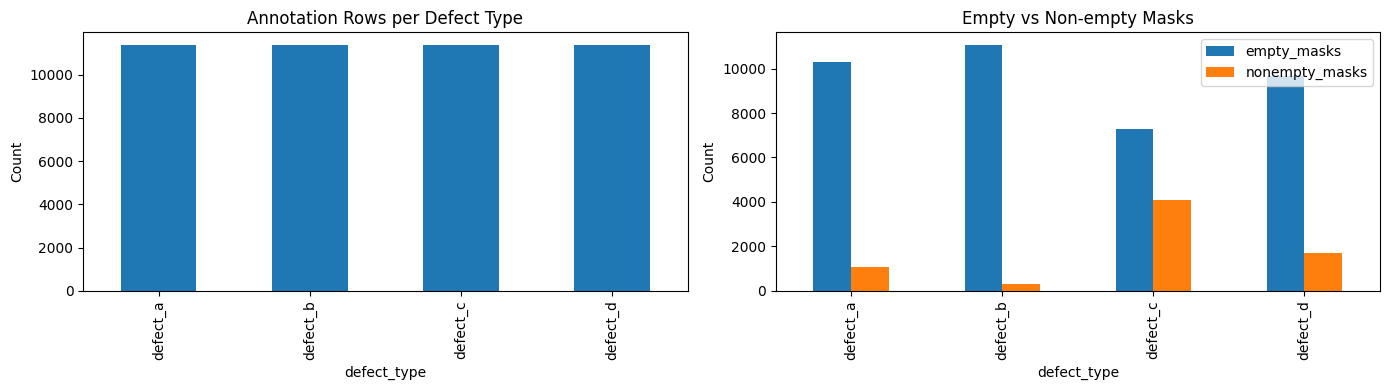

In [7]:
category_summary = train_df.groupby("defect_type").agg(
    annotation_rows=("image_id", "size"),
    unique_images=("image_id", "nunique"),
    empty_masks=("is_empty", "sum")
)
category_summary["nonempty_masks"] = (
    category_summary["annotation_rows"] - category_summary["empty_masks"]
)
category_summary["empty_percent"] = (
    100 * category_summary["empty_masks"] / category_summary["annotation_rows"]
)

print("\nCategory summary:")
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train_df["defect_type"].value_counts().plot(
    kind="bar", ax=axes[0], title="Annotation Rows per Defect Type"
)
category_summary[["empty_masks", "nonempty_masks"]].plot(
    kind="bar", ax=axes[1], title="Empty vs Non-empty Masks"
)
axes[0].set_ylabel("Count")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

In [8]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
train_images = sorted(
    p for p in TRAIN_IMG_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
test_images = sorted(
    p for p in TEST_IMG_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

print("Training image files:", len(train_images))
print("Annotated image IDs:", train_df["image_id"].nunique())
print("Test image files:", len(test_images))
print("Template image IDs:", sample_df["image_id"].nunique())

image_path_map = {p.stem: p for p in train_images}
test_image_ids = {p.stem for p in test_images}

annotated_ids = set(train_df["image_id"].astype(str))
print("Annotated IDs without matching image files:",
      len(annotated_ids - set(image_path_map)))
print("Test image files without template IDs:",
      len(test_image_ids - set(sample_df["image_id"].astype(str))))

Training image files: 11393
Annotated image IDs: 11393
Test image files: 3000
Template image IDs: 3000
Annotated IDs without matching image files: 0
Test image files without template IDs: 0


In [9]:
image_info = []
for path in train_images:
    try:
        with Image.open(path) as img:
            image_info.append({
                "filename": path.name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode
            })
    except Exception as e:
        print("Could not read:", path.name, e)

image_info_df = pd.DataFrame(image_info)

print("\nImage dimensions:")
display(
    image_info_df.groupby(["width", "height"]).size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
print("\nImage modes:")
display(image_info_df["mode"].value_counts())


Image dimensions:


,width,height,count
0,800,128,11393



Image modes:


mode
RGB    11393
Name: count, dtype: int64

In [10]:
# RLE DECODER - COLUMN-MAJOR ORDER
def decode_rle(mask_rle, height, width):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(mask_rle) or str(mask_rle).strip() == "":
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(mask_rle).split(), dtype=np.int64)

    if len(values) % 2 != 0:
        raise ValueError("RLE must contain start-length pairs")

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        if start < 0 or length < 0 or start + length > len(mask):
            raise ValueError("RLE values exceed image dimensions")
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")


Mask statistics:


mask_pixels                                                   \
                  count         mean          std  min  25%  50%     75%   
defect_type                                                                
defect_a        11393.0    71.042570   320.887046  0.0  0.0  0.0     0.0   
defect_b        11393.0    18.932766   131.422300  0.0  0.0  0.0     0.0   
defect_c        11393.0  2000.114456  5827.214260  0.0  0.0  0.0  1253.0   
defect_d        11393.0  1071.315194  3599.848723  0.0  0.0  0.0     0.0   

                     coverage_percent                                     \
                 max            count      mean       std  min  25%  50%   
defect_type                                                                
defect_a      7827.0          11393.0  0.069378  0.313366  0.0  0.0  0.0   
defect_b      2992.0          11393.0  0.018489  0.128342  0.0  0.0  0.0   
defect_c     89138.0          11393.0  1.953237  5.690639  0.0  0.0  0.0   
defect_d     50138.0          11393.0  1.046206  3.515477  0.0  0.0  0.0   

                                  
                  75%        max  
defect_type                       
defect_a     0.000000   7.643555  
defect_b     0.000000   2.921875  
defect_c     1.223633  87.048828  
defect_d     0.000000  48.962891

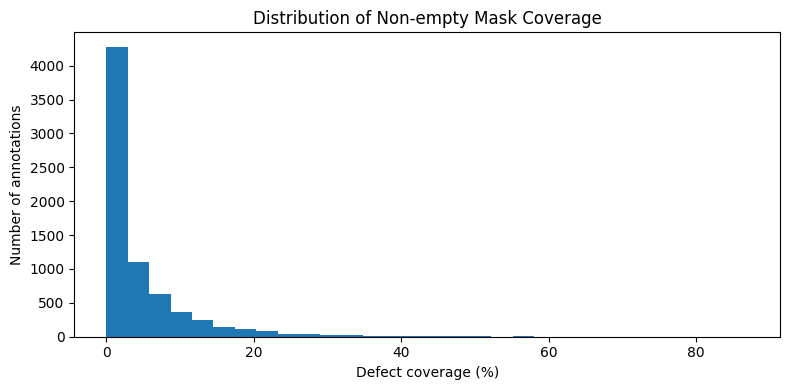

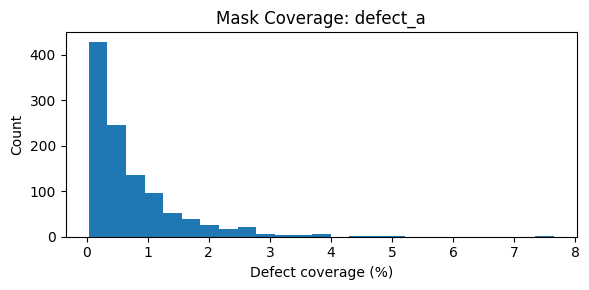

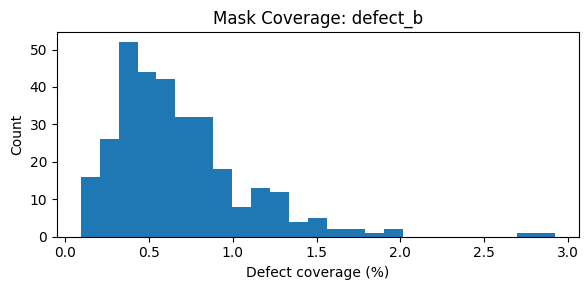

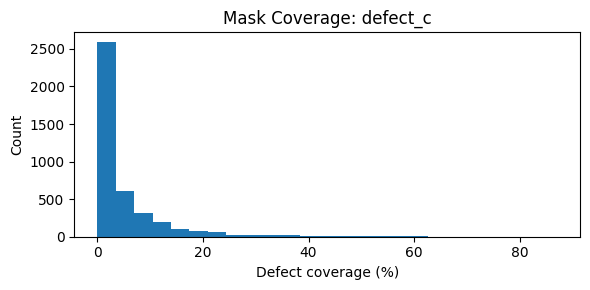

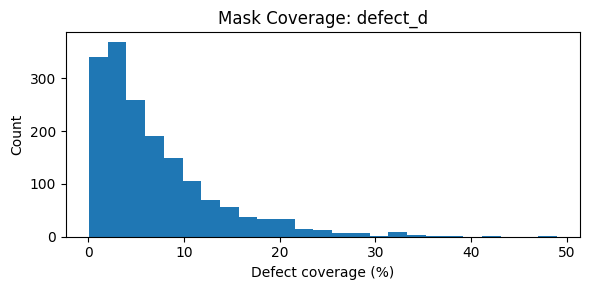

In [11]:
# MASK AREA AND COVERAGE STATISTICS
mask_stats = []

for _, row in train_df.iterrows():
    path = image_path_map.get(str(row["image_id"]))
    if path is None:
        continue

    try:
        with Image.open(path) as img:
            width, height = img.size

        mask = decode_rle(row["mask_rle"], height, width)
        pixels = int(mask.sum())

        mask_stats.append({
            "image_id": row["image_id"],
            "defect_type": row["defect_type"],
            "mask_pixels": pixels,
            "coverage_percent": 100 * pixels / (height * width),
            "is_empty": pixels == 0
        })
    except Exception as e:
        print(f"Mask error for {row['image_id']}: {e}")

mask_stats_df = pd.DataFrame(mask_stats)

print("\nMask statistics:")
if not mask_stats_df.empty:
    display(
        mask_stats_df.groupby("defect_type")[
            ["mask_pixels", "coverage_percent"]
        ].describe()
    )

    positive_coverage = mask_stats_df.loc[
        mask_stats_df["mask_pixels"] > 0, "coverage_percent"
    ]

    plt.figure(figsize=(8, 4))
    plt.hist(positive_coverage, bins=30)
    plt.xlabel("Defect coverage (%)")
    plt.ylabel("Number of annotations")
    plt.title("Distribution of Non-empty Mask Coverage")
    plt.tight_layout()
    plt.show()

    for defect in sorted(mask_stats_df["defect_type"].unique()):
        values = mask_stats_df.loc[
            (mask_stats_df["defect_type"] == defect)
            & (mask_stats_df["mask_pixels"] > 0),
            "coverage_percent"
        ]
        plt.figure(figsize=(6, 3))
        plt.hist(values, bins=25)
        plt.xlabel("Defect coverage (%)")
        plt.ylabel("Count")
        plt.title(f"Mask Coverage: {defect}")
        plt.tight_layout()
        plt.show()

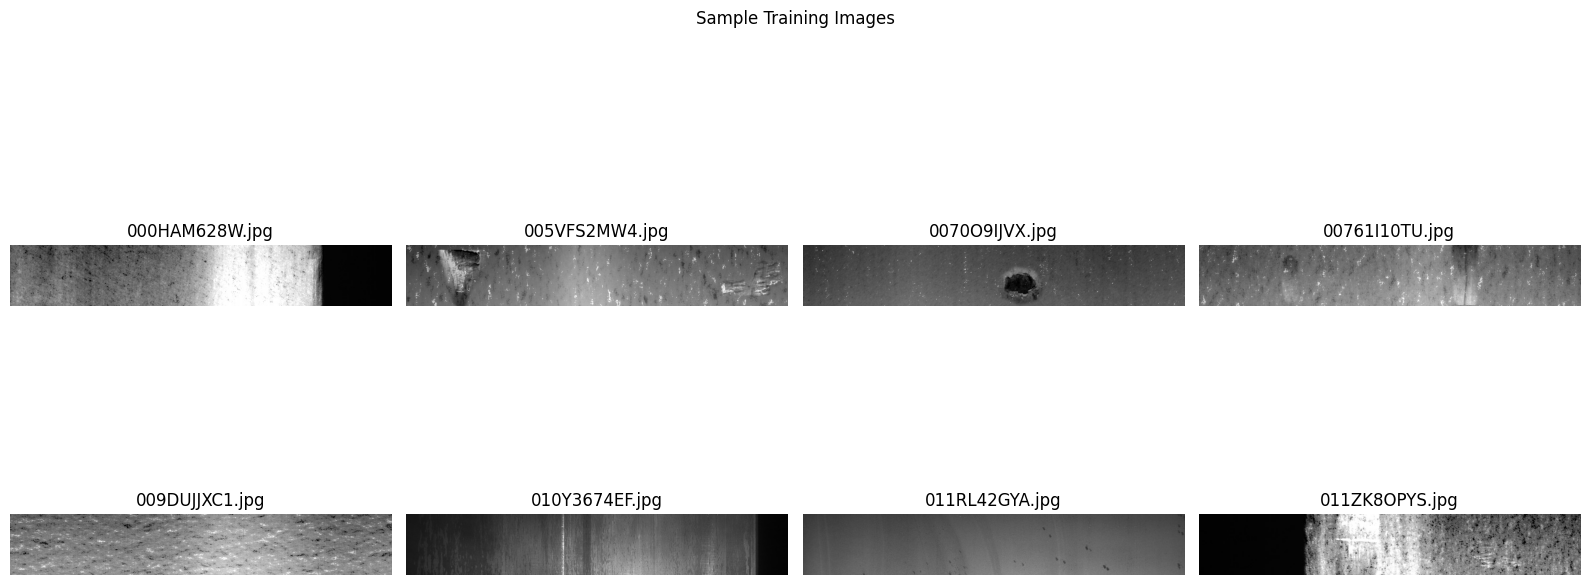

In [12]:
# DISPLAY SAMPLE TRAINING IMAGES
n = min(8, len(train_images))
if n > 0:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for ax, path in zip(axes, train_images[:n]):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(path.name)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.suptitle("Sample Training Images")
    plt.tight_layout()
    plt.show()

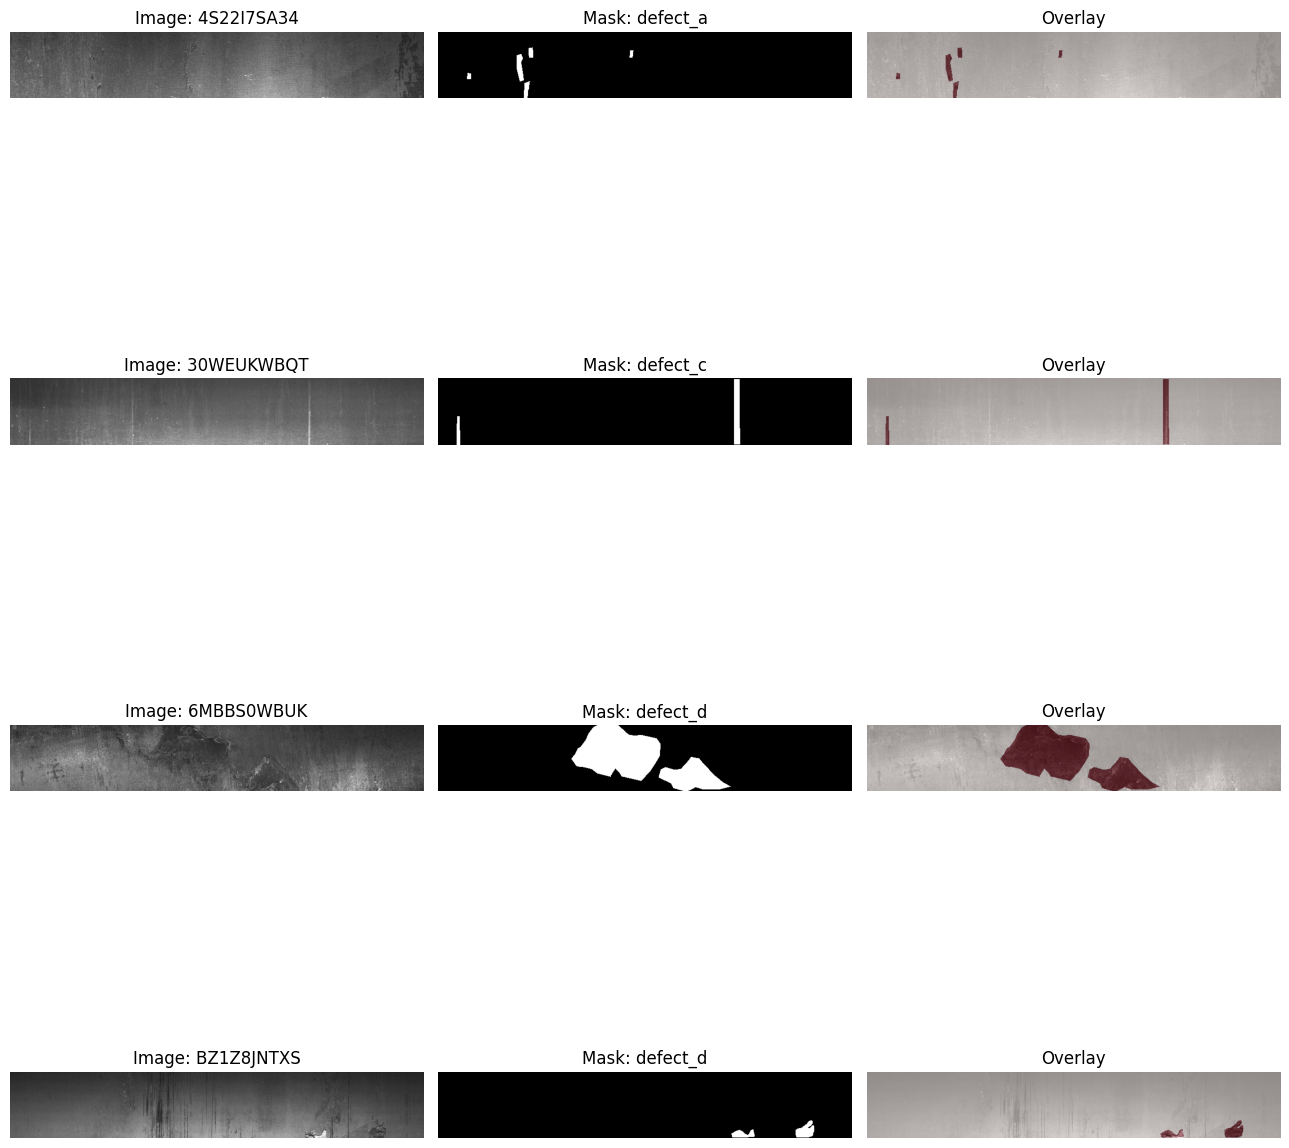

In [13]:
# DISPLAY SAMPLE GROUND-TRUTH MASKS AND OVERLAYS
nonempty = train_df[~train_df["is_empty"]]
n = min(4, len(nonempty))

if n > 0:
    fig, axes = plt.subplots(n, 3, figsize=(13, 4 * n))
    axes = np.atleast_2d(axes)

    shown = 0
    for _, row in nonempty.iterrows():
        path = image_path_map.get(str(row["image_id"]))
        if path is None:
            continue

        with Image.open(path) as img:
            image = np.array(img.convert("RGB"))
            width, height = img.size

        try:
            mask = decode_rle(row["mask_rle"], height, width)
        except ValueError as e:
            print("Skipping invalid mask:", row["image_id"], e)
            continue

        axes[shown, 0].imshow(image)
        axes[shown, 0].set_title(f"Image: {row['image_id']}")
        axes[shown, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[shown, 1].set_title(f"Mask: {row['defect_type']}")
        axes[shown, 2].imshow(image)
        axes[shown, 2].imshow(mask, cmap="Reds", alpha=0.5)
        axes[shown, 2].set_title("Overlay")

        for ax in axes[shown]:
            ax.axis("off")

        shown += 1
        if shown == n:
            break

    for i in range(shown, n):
        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [14]:
print("Columns:", sample_df.columns.tolist())
print("Rows:", len(sample_df))
print("Unique image IDs:", sample_df["image_id"].nunique())
print("\nRows per image:")
display(sample_df.groupby("image_id").size().value_counts().sort_index())
print("\nDefect category counts:")
display(sample_df["defect_type"].value_counts())

Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Rows: 12000
Unique image IDs: 3000

Rows per image:


4    3000
Name: count, dtype: int64


Defect category counts:


defect_type
defect_a    3000
defect_b    3000
defect_c    3000
defect_d    3000
Name: count, dtype: int64

Defect presence per category:


,positive_images
defect_type,
defect_a,1081
defect_b,313
defect_c,4100
defect_d,1707


Number of images containing each pair of defects:


defect_type,defect_a,defect_b,defect_c,defect_d
defect_type,,,,
defect_a,1081,42,310,234
defect_b,42,313,95,64
defect_c,310,95,4100,705
defect_d,234,64,705,1707


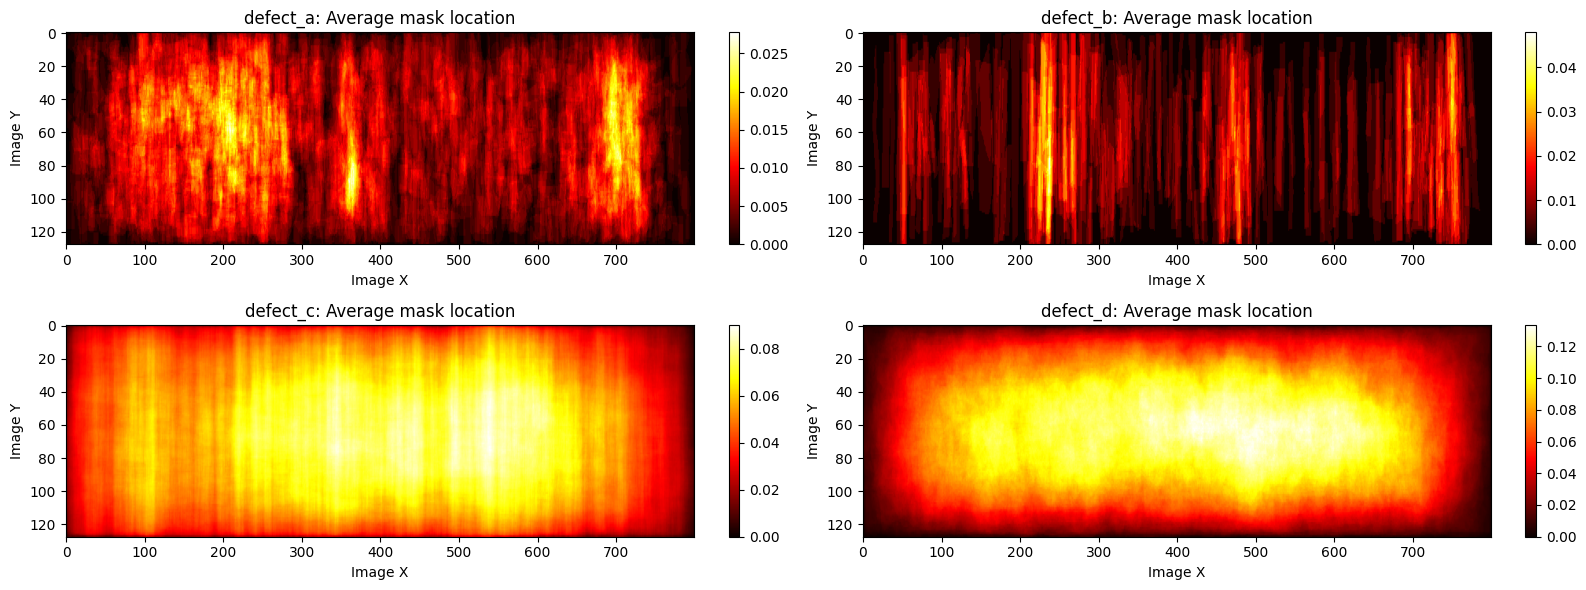

Bounding-box and connected-region statistics:


,area_median,bbox_width_median,bbox_height_median,regions_median,regions_max
defect_type,,,,,
defect_a,472.0,18.0,44.0,1.0,18
defect_b,620.0,11.0,90.0,1.0,3
defect_c,2313.0,96.0,123.0,2.0,73
defect_d,5143.0,120.0,83.0,1.0,27


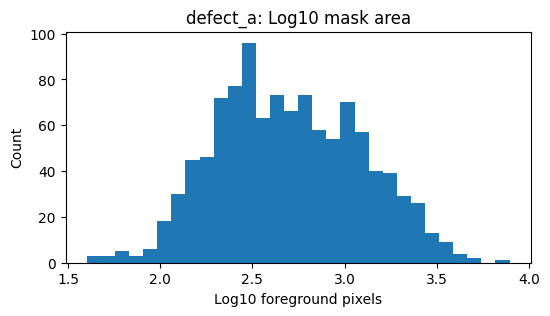

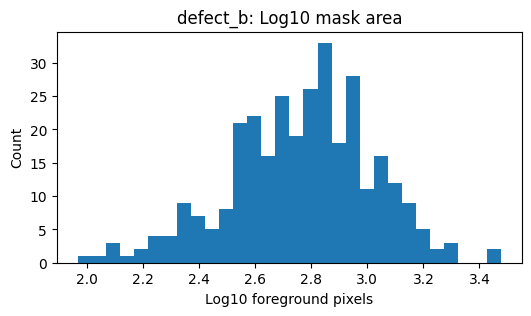

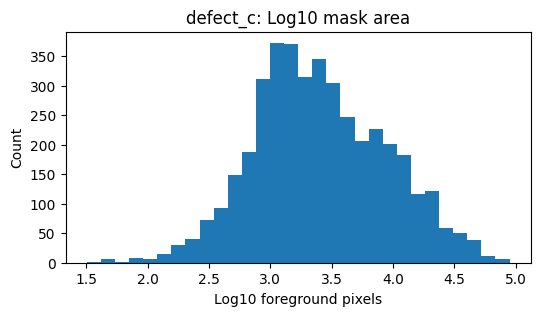

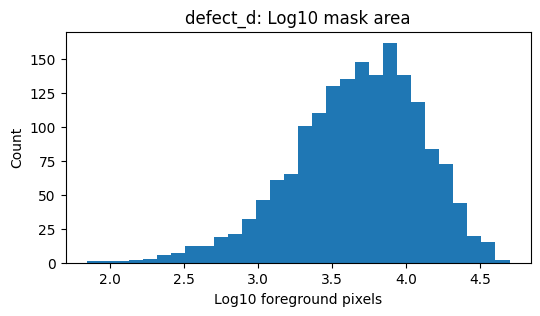

In [15]:

# FURTHER EDA: SPATIAL PATTERNS & CO-OCCURRENCE

import random

DEFECTS = sorted(train_df["defect_type"].unique())

# 1. Which defect categories occur together?
presence = (
    train_df.assign(
        has_defect=train_df["mask_rle"].fillna("").astype(str).str.strip().ne("")
    )
    .pivot(index="image_id", columns="defect_type", values="has_defect")
    .fillna(False)
    .astype(int)
)

print("Defect presence per category:")
display(presence.sum().to_frame("positive_images"))

print("Number of images containing each pair of defects:")
display(presence.T.dot(presence))

# 2. Spatial heatmaps of positive mask pixels
# Each heatmap shows where defects tend to occur across the image.
spatial_maps = {
    defect: np.zeros((128, 800), dtype=np.float64)
    for defect in DEFECTS
}
positive_counts = {defect: 0 for defect in DEFECTS}

for _, row in train_df.iterrows():
    rle = row["mask_rle"]
    if pd.isna(rle) or not str(rle).strip():
        continue

    path = image_path_map.get(str(row["image_id"]))
    if path is None:
        continue

    mask = decode_rle(rle, int(row["height"]), int(row["width"]))

    if mask.shape != (128, 800):
        mask = np.array(
            Image.fromarray(mask).resize((800, 128), resample=Image.Resampling.NEAREST)
        )

    spatial_maps[row["defect_type"]] += mask
    positive_counts[row["defect_type"]] += 1

fig, axes = plt.subplots(2, 2, figsize=(16, 6))

for ax, defect in zip(axes.flat, DEFECTS):
    if positive_counts[defect] > 0:
        heatmap = spatial_maps[defect] / positive_counts[defect]
        im = ax.imshow(heatmap, cmap="hot", aspect="auto")
        ax.set_title(f"{defect}: Average mask location")
        ax.set_xlabel("Image X")
        ax.set_ylabel("Image Y")
        plt.colorbar(im, ax=ax, fraction=0.03)

plt.tight_layout()
plt.show()

# 3. Defect bounding boxes and approximate connected-region counts
try:
    from scipy.ndimage import label

    region_stats = []

    for _, row in train_df[train_df["mask_rle"].fillna("").astype(str).str.strip().ne("")].iterrows():
        path = image_path_map.get(str(row["image_id"]))
        if path is None:
            continue

        mask = decode_rle(row["mask_rle"], int(row["height"]), int(row["width"]))
        ys, xs = np.where(mask > 0)

        if len(xs) == 0:
            continue

        _, n_components = label(mask)

        region_stats.append({
            "defect_type": row["defect_type"],
            "area_pixels": int(mask.sum()),
            "bbox_width": int(xs.max() - xs.min() + 1),
            "bbox_height": int(ys.max() - ys.min() + 1),
            "connected_regions": int(n_components)
        })

    region_df = pd.DataFrame(region_stats)

    print("Bounding-box and connected-region statistics:")
    display(region_df.groupby("defect_type").agg(
        area_median=("area_pixels", "median"),
        bbox_width_median=("bbox_width", "median"),
        bbox_height_median=("bbox_height", "median"),
        regions_median=("connected_regions", "median"),
        regions_max=("connected_regions", "max")
    ))

    for defect in DEFECTS:
        vals = region_df.loc[
            region_df["defect_type"] == defect, "area_pixels"
        ]
        plt.figure(figsize=(6, 3))
        plt.hist(np.log10(vals.clip(lower=1)), bins=30)
        plt.title(f"{defect}: Log10 mask area")
        plt.xlabel("Log10 foreground pixels")
        plt.ylabel("Count")
        plt.show()

except ImportError:
    print("Install scipy to calculate connected-region statistics.")


defect_a: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_a                                                                       
Defect present              44  77.784746  81.656811  25.909409           44   
Mask empty                 456  88.976304  93.972988  31.178341          456   

                                                 
                     mean     median        std  
defect_a                                         
Defect present  37.550984  35.090883  14.202190  
Mask empty      34.046517  30.418202  15.077949

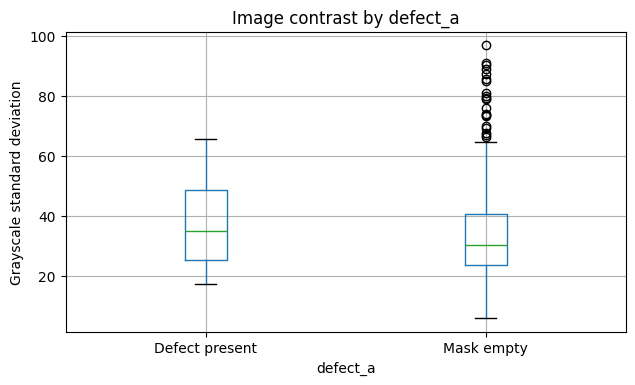


defect_b: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_b                                                                       
Defect present              15  61.132597  70.945412  37.490694           15   
Mask empty                 485  88.822133  93.238632  30.334191          485   

                                                 
                     mean     median        std  
defect_b                                         
Defect present  39.975284  39.528362  19.570155  
Mask empty      34.181084  30.822752  14.851707

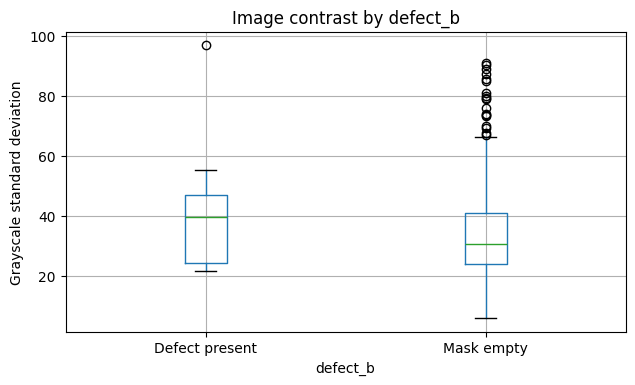


defect_c: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_c                                                                       
Defect present             182  86.978493  91.458778  31.404336          182   
Mask empty                 318  88.571187  93.207138  30.629085          318   

                                                 
                     mean     median        std  
defect_c                                         
Defect present  37.999071  35.891710  14.897054  
Mask empty      32.269258  28.580056  14.714919

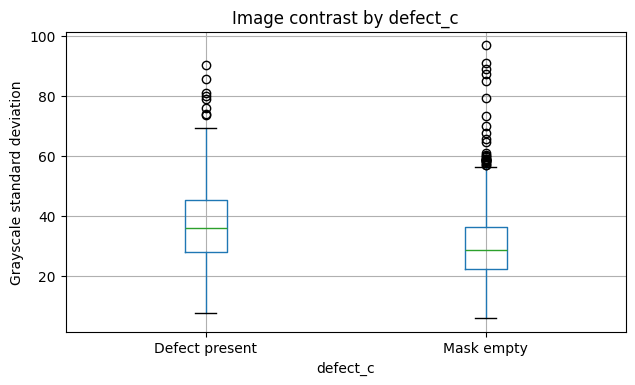


defect_d: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_d                                                                       
Defect present              77  91.052531  91.173454  29.991171           77   
Mask empty                 423  87.434228  93.064056  31.054903          423   

                                                 
                     mean     median        std  
defect_d                                         
Defect present  37.338685  33.450668  16.243488  
Mask empty      33.811765  30.199841  14.744652

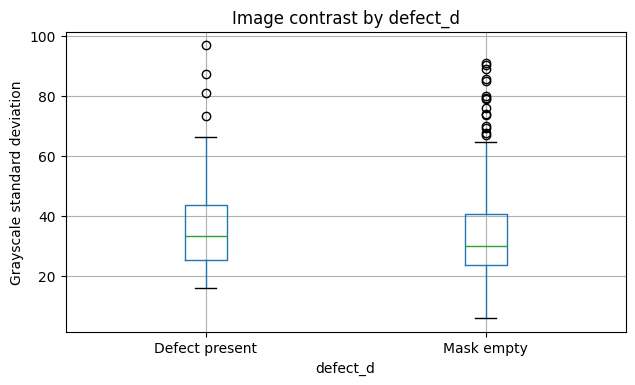

In [16]:

# IMAGE APPEARANCE
rng = np.random.default_rng(42)
sample_ids = rng.choice(
    train_df["image_id"].unique(),
    size=min(500, train_df["image_id"].nunique()),
    replace=False
)

appearance = []

for image_id in sample_ids:
    path = image_path_map.get(str(image_id))
    if path is None:
        continue

    with Image.open(path) as img:
        gray = np.asarray(img.convert("L"), dtype=np.float32)

    row = {
        "image_id": image_id,
        "mean_brightness": float(gray.mean()),
        "contrast_std": float(gray.std())
    }

    for defect in DEFECTS:
        mask_row = train_df[
            (train_df["image_id"] == image_id)
            & (train_df["defect_type"] == defect)
        ]

        row[defect] = (
            len(mask_row) > 0
            and mask_row["mask_rle"].fillna("").astype(str).str.strip().ne("").any()
        )

    appearance.append(row)

appearance_df = pd.DataFrame(appearance)

for defect in DEFECTS:
    appearance_df[defect] = appearance_df[defect].map({
        True: "Defect present",
        False: "Mask empty"
    })

    print(f"\n{defect}: brightness and contrast")
    display(
        appearance_df.groupby(defect)[
            ["mean_brightness", "contrast_std"]
        ].agg(["count", "mean", "median", "std"])
    )

    appearance_df.boxplot(
        column="contrast_std",
        by=defect,
        figsize=(7, 4)
    )
    plt.title(f"Image contrast by {defect}")
    plt.suptitle("")
    plt.ylabel("Grayscale standard deviation")
    plt.show()
